# Retrieval — IR-based Factoid QA
Demonstrates **Steps 4–8**: TF-IDF vectorisation, cosine similarity, top-passage retrieval, answer extraction and confidence scoring.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from src.retriever import TfidfRetriever

In [2]:
retriever = TfidfRetriever()
print('Vocabulary size:', len(retriever.vectorizer.vocabulary_))
print('Passage matrix shape:', retriever.matrix.shape)

Vocabulary size: 1386
Passage matrix shape: (40, 1386)


## Retrieve top-3 passages for a question

In [3]:
results = retriever.retrieve('What is machine learning?', top_k=3)
for r in results:
    print(f"{r['score']:.3f}  {r['doc']} (para {r['para_id']})")
    print('   ', r['text'][:100], '...')

0.360  02_machine_learning (para 0)
    Machine learning is a subfield of artificial intelligence in which computers learn patterns from dat ...
0.317  10_unsupervised_learning (para 0)
    Unsupervised learning is a type of machine learning that finds hidden patterns in data without label ...
0.305  02_machine_learning (para 1)
    The three main paradigms of machine learning are supervised learning, unsupervised learning and rein ...


## Full answer pipeline (retrieve + extract + confidence)

In [4]:
questions = [
    'What is machine learning?',
    'How does backpropagation train a neural network?',
    'What is overfitting and how can it be reduced?',
    'Which architecture uses self-attention?',
    'What is the weather today?',
]
for q in questions:
    a = retriever.answer(q)
    print('Q:', q)
    if a:
        print(f"  Confidence: {a['confidence']:.2f}  Source: {a['source']}")
        print('  A:', a['answer'])
    else:
        print('  (no confident match - fallback)')
    print()

Q: What is machine learning?
  Confidence: 0.36  Source: 02_machine_learning
  A: Machine learning is a subfield of artificial intelligence in which computers learn patterns from data instead of being explicitly programmed with rules.

Q: How does backpropagation train a neural network?
  Confidence: 0.29  Source: 04_neural_networks
  A: Neural networks are trained using the backpropagation algorithm, which computes the error at the output and propagates it backwards to update the weights using gradient descent.

Q: What is overfitting and how can it be reduced?
  Confidence: 0.26  Source: 12_overfitting_and_underfitting
  A: Overfitting can be reduced by collecting more data, using regularization, applying dropout, using cross-validation and stopping training early.

Q: Which architecture uses self-attention?
  Confidence: 0.37  Source: 05_natural_language_processing
  A: Modern NLP relies on the Transformer architecture, which uses self-attention to model relationships between words.

## Visualising similarity scores for one question

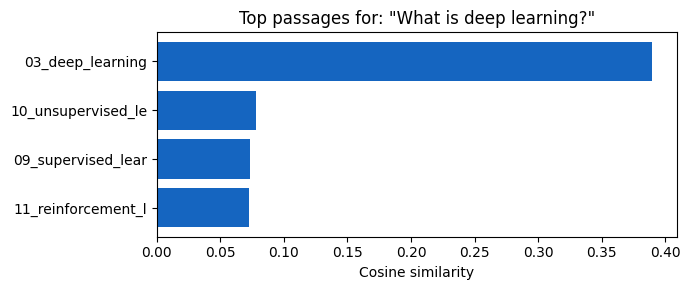

In [5]:
import matplotlib.pyplot as plt
q = 'What is deep learning?'
res = retriever.retrieve(q, top_k=5)
labels = [f"{r['doc'][:18]}" for r in res]
scores = [r['score'] for r in res]
plt.figure(figsize=(7,3))
plt.barh(labels[::-1], scores[::-1], color='#1565c0')
plt.xlabel('Cosine similarity'); plt.title(f'Top passages for: "{q}"')
plt.tight_layout(); plt.show()